# Hạn chế của K-means (mục 8.1.3, 8.1.4)

(a) cụm hình dạng không lồi, (b) phân cụm phân cấp single linkage trên cùng dữ liệu,
(c) cụm có kích thước và độ phân tán khác nhau

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs, make_moons

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

X_moons, _ = make_moons(n_samples=300, noise=0.05, random_state=0)
X_blobs, _ = make_blobs(n_samples=[400, 40, 40], centers=[[0, 0], [5, 2.5], [5, -2.5]],
                        cluster_std=[2.0, 0.4, 0.4], random_state=1)

Vẽ hình và lưu ảnh.

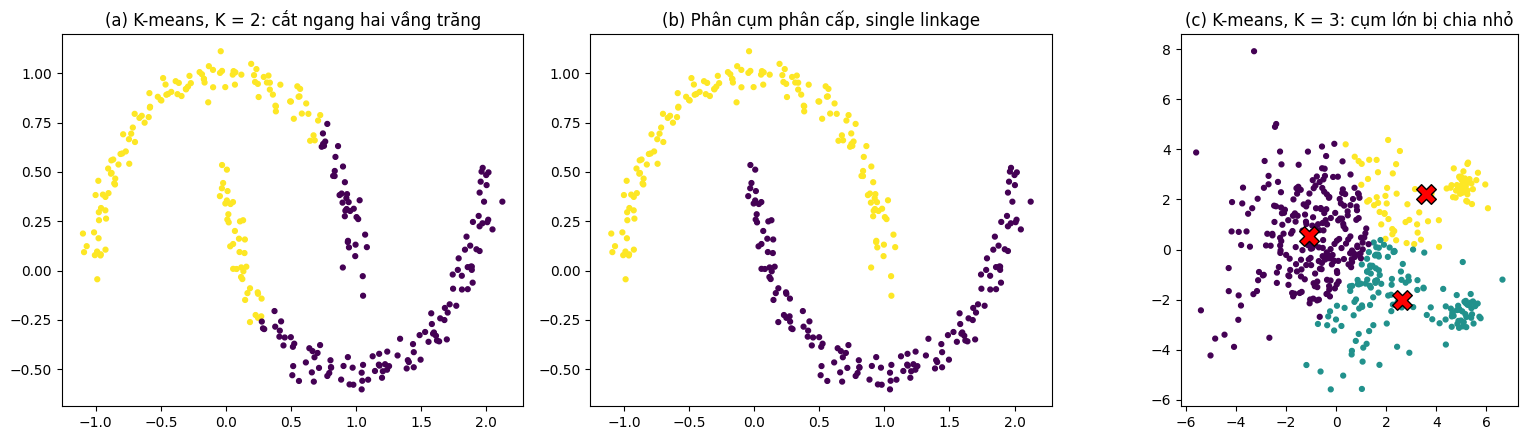

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_moons)
axes[0].scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap='viridis', s=12)
axes[0].set_title('(a) K-means, K = 2: cắt ngang hai vầng trăng')
labels = AgglomerativeClustering(n_clusters=2, linkage='single').fit_predict(X_moons)
axes[1].scatter(X_moons[:, 0], X_moons[:, 1], c=labels, cmap='viridis', s=12)
axes[1].set_title('(b) Phân cụm phân cấp, single linkage')
model = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X_blobs)
axes[2].scatter(X_blobs[:, 0], X_blobs[:, 1], c=model.labels_, cmap='viridis', s=12)
axes[2].scatter(*model.cluster_centers_.T, marker='X', s=200, c='red', edgecolors='k')
axes[2].set_title('(c) K-means, K = 3: cụm lớn bị chia nhỏ')
axes[2].set_aspect('equal')
fig.tight_layout()
fig.savefig(IMAGES / 'kmeans_limitations.png', dpi=150)